# Notebook 15: Zelfde tijd gisteren (persistence)
---
- De simpelste voorspelling: het verbruik of de opwek van morgen is gelijk aan dat van **hetzelfde tijdstip gisteren**
- Voor dag 2 en 3 van de forecast wordt de laatst bekende dag herhaald (er is nog geen nieuwe data)
- Wordt als eigen "model" opgeslagen in `models/results/`, zodat hij als referentiepunt in de vergelijkingsgrafieken staat
- Zelfde vensters en zelfde scorefunctie als de andere modellen: de split uit `06_Dataprep_v3` (stap 4.0) en de rolling evaluatie uit `models/evaluatie.py`

### 1. Waarom deze baseline?
---
- Een model is pas nuttig als het beter is dan een voorspelling die geen enkele moeite kost (Hyndman & Athanasopoulos, 2021)
- Bij energiedata met een sterk dagpatroon is *seasonal naive* (zelfde tijd vorige periode) een sterke en veelgebruikte referentie
- In notebook 14 is de relatieve MAE van dit model per definitie 1

**Bron**
- Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and Practice* (3rd ed.), hoofdstuk 5.2 "Some simple forecasting methods". OTexts. https://otexts.com/fpp3/

### 2. Inladen
---

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

#Projectmap zoeken, werkt vanuit elke submap van models/
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "prepared_data").exists())
sys.path.append(str(ROOT / "models"))

import evaluatie as ev

RESULTS_DIR = ROOT / "models" / "results"
MODEL_DIR = ROOT / "models" / "saved_models"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

### 3. Instellingen
---
- Validatie en test zijn de vaste seizoensvensters uit `06_Dataprep_v3`, elk uur een nieuwe forecast
- Deze baseline gebruikt geen weer en leest daarom `forecast_targets_long.parquet`

In [2]:
stap_per_dag = ev.PUNTEN_PER_DAG
aantal_dagen_input = 7
input_len = aantal_dagen_input * stap_per_dag
aantal_dagen_forecast = 3
horizon = aantal_dagen_forecast * stap_per_dag
stride_eval = 12

LOCATIE = "huis"
TARGETS = {"consumption": "15_Persistence_huis_cons", "generation": "15_Persistence_huis_gen"}
MODEL_NAAM = "Zelfde tijd gisteren"

### 4. Voorspellen en scoren
---
- Er wordt niets getraind. De voorspelling is de laatste dag vóór het forecastmoment, 3 keer herhaald (`ev.seasonal_naive`)
- In validatie en test is niets ingevuld. Ontbreekt er een punt in die laatste dag, dan wordt het gevuld met data van eerder (`ev.vul_input`, kijkt alleen terug)
- `ev.rolling_evaluatie` scoort op 5, 10, 15, 30 en 60 minuten en 1, 2 en 3 dagen vooruit, alleen tegen echte metingen
- Modelgrootte = de laatst bekende dag (288 waarden), meer heeft deze methode niet nodig

In [3]:
def scores(pred, echt):
    fout = pred - echt                               #NaN waar geen echte meting is
    res = {"MAE": np.nanmean(np.abs(fout)), "RMSE": np.sqrt(np.nanmean(fout ** 2))}
    for d in range(aantal_dagen_forecast):
        s = slice(d * stap_per_dag, (d + 1) * stap_per_dag)
        res[f"MAE dag {d+1}"] = np.nanmean(np.abs(fout[:, s]))
    #Rolling validation: elke dag een nieuwe forecast
    dagelijks = slice(None, None, stap_per_dag // stride_eval)
    res["rolling MAE"] = np.nanmean(np.nanmean(np.abs(fout[dagelijks]), axis=1))
    res["rolling RMSE"] = np.nanmean(np.sqrt(np.nanmean(fout[dagelijks] ** 2, axis=1)))
    return res


def evalueer(target, notebook):
    data = ev.laad_reeks(LOCATIE, target)
    voorspel = ev.seasonal_naive(data)

    val_origins = ev.maak_origins(data, "val", stap=stride_eval, horizon=horizon)
    test_origins = ev.maak_origins(data, "test", stap=stride_eval, horizon=horizon)

    #Rolling evaluatie op de vaste horizons, validatie en test
    detail_val = ev.rolling_evaluatie(voorspel, data, val_origins)
    detail_test = ev.rolling_evaluatie(voorspel, data, test_origins)
    ev.bewaar(detail_val, notebook.lower(), LOCATIE, target)
    ev.bewaar(detail_test, notebook.lower(), LOCATIE, target)

    per_horizon = pd.DataFrame({"aantal val": ev.samenvatting(detail_val)["aantal"],
                                "MAE val": ev.samenvatting(detail_val)["MAE"],
                                "RMSE val": ev.samenvatting(detail_val)["RMSE"],
                                "aantal test": ev.samenvatting(detail_test)["aantal"],
                                "MAE test": ev.samenvatting(detail_test)["MAE"],
                                "RMSE test": ev.samenvatting(detail_test)["RMSE"]}).reindex(list(ev.HORIZONS)).round(1)

    #Overzicht in het oude format, op de testvensters en alleen tegen echte metingen
    echt_arr = data["pow_w"].to_numpy(np.float64)
    h = np.arange(horizon)
    t = test_origins[:, None] + h[None, :]
    echt = echt_arr[t]

    t0 = time.perf_counter()
    pred = voorspel(test_origins)
    voorspeltijd = time.perf_counter() - t0
    week = ev.vul_input(echt_arr)[t - input_len]

    resultaten = pd.DataFrame({MODEL_NAAM: scores(pred, echt),
                               "Persistence dag": scores(pred, echt),
                               "Persistence week": scores(week, echt)}).T
    resultaten.loc[MODEL_NAAM, "trainingstijd (s)"] = 0.0
    resultaten = resultaten.round(1)
    resultaten.loc[MODEL_NAAM, "voorspeltijd (s)"] = round(voorspeltijd, 4)

    #Het "model" is alleen de laatst bekende dag
    pad = MODEL_DIR / f"{notebook.lower()}.npy"
    np.save(pad, pred[-1, :stap_per_dag])
    resultaten.loc[MODEL_NAAM, "modelgrootte (MB)"] = round(pad.stat().st_size / 1e6, 4)

    KOLOMMEN = ["notebook", "locatie", "target", "resolutie", "testperiode", "MAE", "RMSE", "MAE dag 1", "MAE dag 2",
                "MAE dag 3", "rolling MAE", "rolling RMSE", "trainingstijd (s)", "voorspeltijd (s)",
                "modelgrootte (MB)"]
    test_tijden = data.loc[data["set"] == "test", "timestamp"]
    resultaten["notebook"] = notebook
    resultaten["locatie"] = LOCATIE
    resultaten["target"] = target
    resultaten["resolutie"] = "5 min"
    resultaten["testperiode"] = f"4 seizoensvensters, {test_tijden.min():%Y-%m-%d} t/m {test_tijden.max():%Y-%m-%d}"
    resultaten = resultaten.reindex(columns=KOLOMMEN)
    resultaten.to_csv(RESULTS_DIR / f"{notebook.lower()}.csv")
    return resultaten, per_horizon, echt_arr, test_origins, pred


uitkomsten = {}
for target, notebook in TARGETS.items():
    resultaten, per_horizon, echt_arr, test_origins, pred = evalueer(target, notebook)
    uitkomsten[target] = (echt_arr, test_origins, pred)
    print(f"\n{target.upper()} ({len(test_origins)} forecasts in test)")
    display(per_horizon)
    display(resultaten)


CONSUMPTION (795 forecasts in test)


,aantal val,MAE val,RMSE val,aantal test,MAE test,RMSE test
horizon,,,,,,
5 min,582,493.1,804.6,703,508.5,834.6
10 min,583,450.5,745.1,713,494.7,836.1
15 min,587,496.0,824.8,716,539.1,895.0
30 min,562,485.9,760.9,710,535.0,836.9
60 min,566,481.0,768.5,704,515.2,851.2
1 dag,577,494.6,793.9,707,507.2,842.6
2 dagen,583,511.5,812.0,711,500.3,816.0
3 dagen,587,478.0,783.2,713,493.9,815.4


,notebook,locatie,target,resolutie,testperiode,MAE,RMSE,MAE dag 1,MAE dag 2,MAE dag 3,rolling MAE,rolling RMSE,trainingstijd (s),voorspeltijd (s),modelgrootte (MB)
Zelfde tijd gisteren,15_Persistence_huis_cons,huis,consumption,5 min,"4 seizoensvensters, 2025-07-03 t/m 2026-04-06",525.7,841.7,534.0,520.0,523.2,517.0,818.7,0.0,0.0026,0.0024
Persistence dag,15_Persistence_huis_cons,huis,consumption,5 min,"4 seizoensvensters, 2025-07-03 t/m 2026-04-06",525.7,841.7,534.0,520.0,523.2,517.0,818.7,NaN,NaN,NaN
Persistence week,15_Persistence_huis_cons,huis,consumption,5 min,"4 seizoensvensters, 2025-07-03 t/m 2026-04-06",515.1,837.1,511.9,514.8,518.7,508.6,818.0,NaN,NaN,NaN



GENERATION (795 forecasts in test)


,aantal val,MAE val,RMSE val,aantal test,MAE test,RMSE test
horizon,,,,,,
5 min,459,285.6,542.2,551,280.2,551.3
10 min,459,294.4,575.6,559,270.9,526.1
15 min,473,271.2,533.0,568,294.1,580.2
30 min,449,309.0,587.8,568,273.7,537.1
60 min,455,289.0,554.6,552,283.0,560.2
1 dag,457,273.5,528.9,559,268.8,541.7
2 dagen,460,246.6,471.2,559,269.8,542.8
3 dagen,455,266.4,516.6,565,269.1,539.4


,notebook,locatie,target,resolutie,testperiode,MAE,RMSE,MAE dag 1,MAE dag 2,MAE dag 3,rolling MAE,rolling RMSE,trainingstijd (s),voorspeltijd (s),modelgrootte (MB)
Zelfde tijd gisteren,15_Persistence_huis_gen,huis,generation,5 min,"4 seizoensvensters, 2025-07-03 t/m 2026-04-06",280.9,546.9,273.7,281.8,287.0,278.9,458.8,0.0,0.0021,0.0024
Persistence dag,15_Persistence_huis_gen,huis,generation,5 min,"4 seizoensvensters, 2025-07-03 t/m 2026-04-06",280.9,546.9,273.7,281.8,287.0,278.9,458.8,NaN,NaN,NaN
Persistence week,15_Persistence_huis_gen,huis,generation,5 min,"4 seizoensvensters, 2025-07-03 t/m 2026-04-06",298.9,558.9,294.9,297.5,304.4,304.7,491.8,NaN,NaN,NaN


### 5. Voorbeeld
---
- Eén forecast per target: grijs is de historie, de voorspelling is een kopie van de laatste dag
- Lege stukken in de lijnen zijn tijdstippen zonder meting

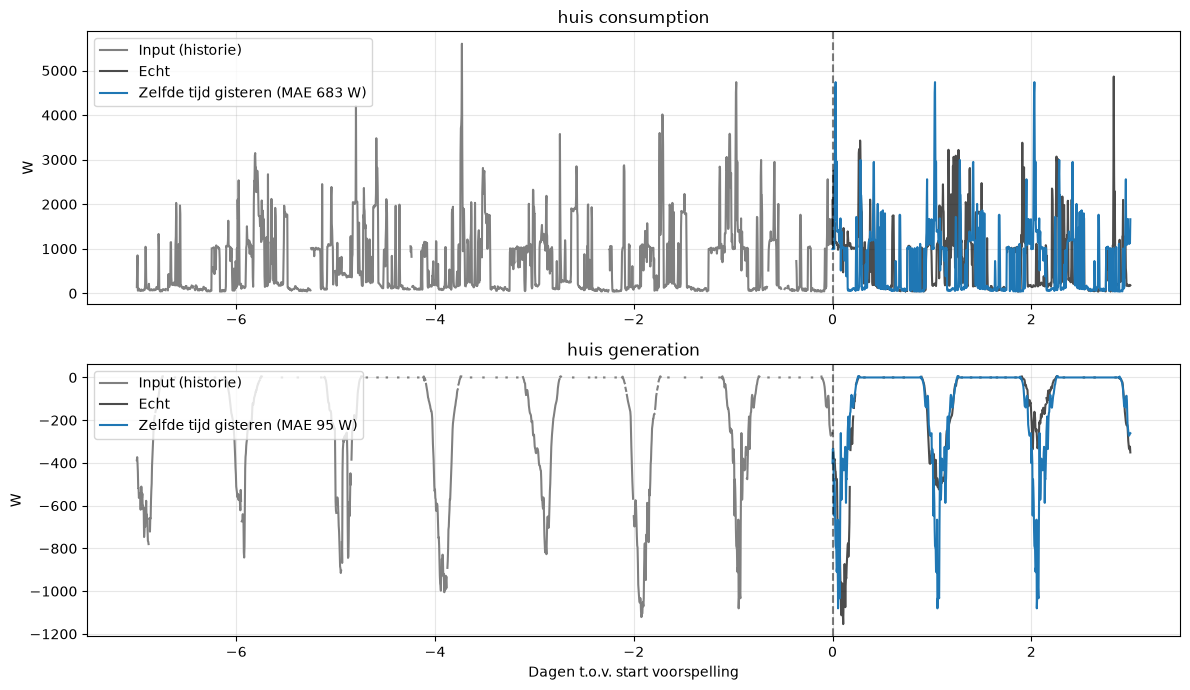

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
for ax, (target, (echt_arr, test_origins, pred)) in zip(axes, uitkomsten.items()):
    idx = len(test_origins) // 2
    o = test_origins[idx]
    t_hist = np.arange(-input_len, 0) / stap_per_dag
    t_fc = np.arange(horizon) / stap_per_dag
    mae = np.nanmean(np.abs(pred[idx] - echt_arr[o:o + horizon]))
    ax.plot(t_hist, echt_arr[o - input_len:o], color="grey", label="Input (historie)")
    ax.plot(t_fc, echt_arr[o:o + horizon], color="black", alpha=0.7, label="Echt")
    ax.plot(t_fc, pred[idx], label=f"Zelfde tijd gisteren (MAE {mae:.0f} W)")
    ax.axvline(0, color="black", linestyle="--", alpha=0.5)
    ax.set_title(f"{LOCATIE} {target}")
    ax.set_ylabel("W")
    ax.grid(alpha=0.3)
    ax.legend(loc="upper left")
axes[-1].set_xlabel("Dagen t.o.v. start voorspelling")
plt.tight_layout()
plt.show()